In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
from pylab import rcParams
import warnings
from sklearn.preprocessing import StandardScaler
from math import pi
import seaborn as sns 
from mpl_toolkits.mplot3d import Axes3D
rcParams["figure.figsize"]=(30,18)
plt.rcParams['figure.dpi'] = 300
plt.rcParams['font.weight'] = 'bold'
plt.rcParams['font.size'] = 15
warnings.filterwarnings("ignore")
warnings.simplefilter(action='ignore', category=FutureWarning)
import os
if os.path.exists("EV_Energy_Consumption_Dataset.csv"):
    df = pd.read_csv("EV_Energy_Consumption_Dataset.csv")
    print("Loaded local dataset: EV_Energy_Consumption_Dataset.csv")
else:
    for dirname, _, filenames in os.walk('/kaggle/input'):
        for filename in filenames:
            Path  = os.path.join(dirname, filename)
            print(os.path.join(dirname, filename))
            df = pd.read_csv(Path)

/kaggle/input/datasets/ziya07/ev-energy-consumption-dataset/EV_Energy_Consumption_Dataset.csv


In [ ]:
df

,Vehicle_ID,Timestamp,Speed_kmh,Acceleration_ms2,Battery_State_%,Battery_Voltage_V,Battery_Temperature_C,Driving_Mode,Road_Type,Traffic_Condition,Slope_%,Weather_Condition,Temperature_C,Humidity_%,Wind_Speed_ms,Tire_Pressure_psi,Vehicle_Weight_kg,Distance_Travelled_km,Energy_Consumption_kWh
0,1102,2024-01-01 00:00:00,111.507366,-2.773816,30.415148,378.091525,25.314786,2,1,1,6.879446,4,0.741770,42.172533,7.829253,31.112020,1822.967368,20.757508,12.054317
1,1435,2024-01-01 00:01:00,48.612323,-0.796982,97.385534,392.718377,18.240755,1,2,1,-3.007212,4,-3.495516,57.018427,4.495572,31.504366,2091.831914,0.642918,4.488701
2,1860,2024-01-01 00:02:00,108.733320,0.253800,84.912600,398.993495,44.449145,1,1,3,0.029585,1,9.248275,69.028911,5.144489,33.838015,1816.702497,40.842824,11.701377
3,1270,2024-01-01 00:03:00,38.579484,-2.111395,28.777904,358.128273,28.980155,1,2,2,8.271943,3,2.868409,86.638349,4.518283,33.256014,1283.102642,5.305229,7.389266
4,1106,2024-01-01 00:04:00,57.172438,1.477883,29.740160,310.888162,33.184551,2,1,1,2.776814,2,16.750244,27.189185,4.263406,33.579678,2160.350788,5.825926,6.761205
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,1289,2024-01-04 11:15:00,60.036619,-0.685606,78.360306,355.284001,23.338767,2,1,2,0.273436,1,2.678321,73.356245,13.936821,28.327849,1796.093041,47.102202,10.089577
4996,1294,2024-01-04 11:16:00,107.291944,1.674625,68.163963,375.453798,19.056652,2,2,2,9.793821,3,37.105374,78.446046,12.197087,29.155964,2095.099662,7.538642,9.600692
4997,1450,2024-01-04 11:17:00,110.384512,1.348736,72.918142,303.834905,28.155775,1,3,2,-0.429536,1,-2.955831,78.251840,1.595182,34.369795,2328.330539,5.644158,9.148392
4998,1903,2024-01-04 11:18:00,6.618791,-2.642843,91.904887,302.708365,31.781034,2,1,2,-3.366394,3,16.154754,74.929797,13.503355,33.363985,1274.506744,32.768008,5.581431


In [ ]:
df.isnull().sum()

Vehicle_ID                0
Timestamp                 0
Speed_kmh                 0
Acceleration_ms2          0
Battery_State_%           0
Battery_Voltage_V         0
Battery_Temperature_C     0
Driving_Mode              0
Road_Type                 0
Traffic_Condition         0
Slope_%                   0
Weather_Condition         0
Temperature_C             0
Humidity_%                0
Wind_Speed_ms             0
Tire_Pressure_psi         0
Vehicle_Weight_kg         0
Distance_Travelled_km     0
Energy_Consumption_kWh    0
dtype: int64

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Vehicle_ID              5000 non-null   int64  
 1   Timestamp               5000 non-null   object 
 2   Speed_kmh               5000 non-null   float64
 3   Acceleration_ms2        5000 non-null   float64
 4   Battery_State_%         5000 non-null   float64
 5   Battery_Voltage_V       5000 non-null   float64
 6   Battery_Temperature_C   5000 non-null   float64
 7   Driving_Mode            5000 non-null   int64  
 8   Road_Type               5000 non-null   int64  
 9   Traffic_Condition       5000 non-null   int64  
 10  Slope_%                 5000 non-null   float64
 11  Weather_Condition       5000 non-null   int64  
 12  Temperature_C           5000 non-null   float64
 13  Humidity_%              5000 non-null   float64
 14  Wind_Speed_ms           5000 non-null   

In [ ]:
print(f"\nDate Range: {df['Timestamp'].min()} to {df['Timestamp'].max()}")


Date Range: 2024-01-01 00:00:00 to 2024-01-04 11:19:00


In [ ]:
df['Timestamp'] = pd.to_datetime(df['Timestamp'])

In [ ]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
Vehicle_ID,5000.0,1505.7012,1000.0,1253.0,1510.0,1761.0,1999.0,290.836902
Timestamp,5000,2024-01-02 17:39:30,2024-01-01 00:00:00,2024-01-01 20:49:45,2024-01-02 17:39:30,2024-01-03 14:29:15,2024-01-04 11:19:00,NaN
Speed_kmh,5000.0,59.312952,0.001396,29.5154,58.646794,89.030001,119.946924,34.517605
Acceleration_ms2,5000.0,-0.019885,-2.999683,-1.49024,-0.043329,1.473887,2.998039,1.724287
Battery_State_%,5000.0,60.214465,20.020196,40.088318,60.490283,80.409928,99.993986,23.128262
Battery_Voltage_V,5000.0,351.118306,300.004812,326.613439,351.510915,375.96814,399.990098,28.968372
Battery_Temperature_C,5000.0,27.51013,10.003858,18.884742,27.58171,35.920162,44.985943,10.015385
Driving_Mode,5000.0,2.011,1.0,1.0,2.0,3.0,3.0,0.810068
Road_Type,5000.0,1.9992,1.0,1.0,2.0,3.0,3.0,0.808536
Traffic_Condition,5000.0,2.0108,1.0,1.0,2.0,3.0,3.0,0.812167


In [ ]:
print(f"Duplicate Rows: {df.duplicated().sum()}")

Duplicate Rows: 0


In [ ]:
key_features = ['Speed_kmh', 'Acceleration_ms2', 'Battery_State_%', 
                'Battery_Voltage_V', 'Battery_Temperature_C', 'Energy_Consumption_kWh']

outlier_summary = {}

for feature in key_features:
    Q1 = df[feature].quantile(0.25)
    Q3 = df[feature].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[feature] < lower_bound) | (df[feature] > upper_bound)]
    outlier_summary[feature] = {
        'lower_bound': lower_bound,
        'upper_bound': upper_bound,
        'outlier_count': len(outliers),
        'outlier_percentage': (len(outliers) / len(df)) * 100
    }

for feature, stats_dict in outlier_summary.items():
    print(f"\n{feature}:")
    print(f"  Acceptable Range: [{stats_dict['lower_bound']:.2f}, {stats_dict['upper_bound']:.2f}]")
    print(f"  Outliers: {stats_dict['outlier_count']} ({stats_dict['outlier_percentage']:.2f}%)")


Speed_kmh:
  Acceptable Range: [-59.76, 178.30]
  Outliers: 0 (0.00%)

Acceleration_ms2:
  Acceptable Range: [-5.94, 5.92]
  Outliers: 0 (0.00%)

Battery_State_%:
  Acceptable Range: [-20.39, 140.89]
  Outliers: 0 (0.00%)

Battery_Voltage_V:
  Acceptable Range: [252.58, 450.00]
  Outliers: 0 (0.00%)

Battery_Temperature_C:
  Acceptable Range: [-6.67, 61.47]
  Outliers: 0 (0.00%)

Energy_Consumption_kWh:
  Acceptable Range: [1.88, 14.92]
  Outliers: 0 (0.00%)


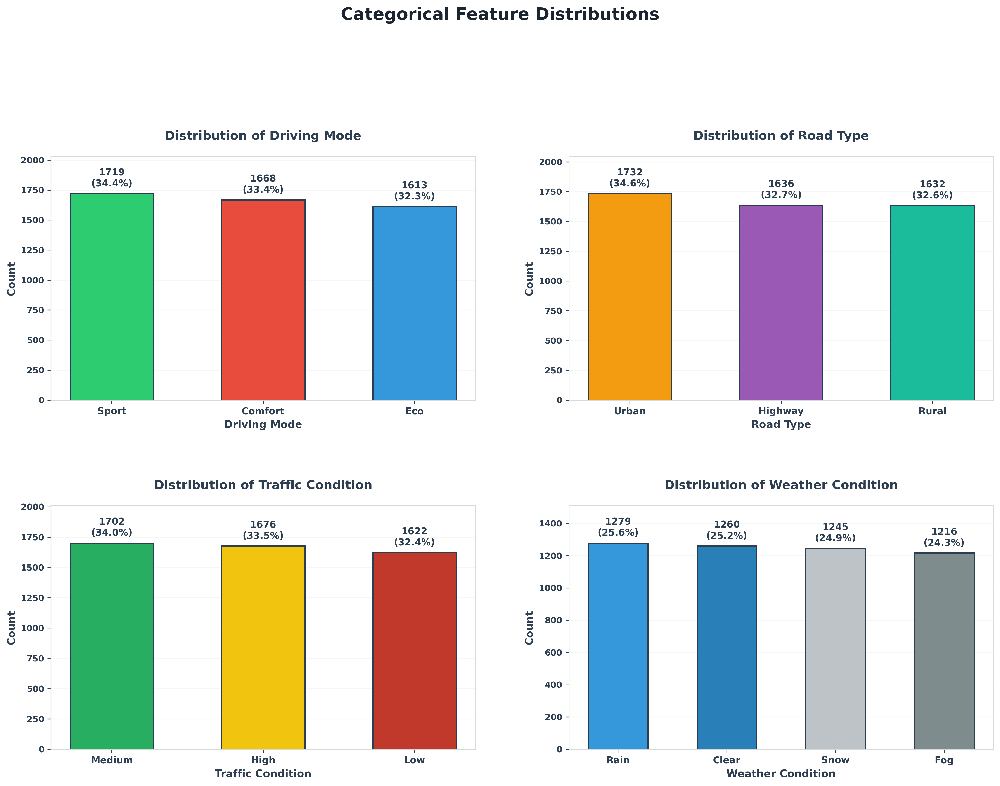

In [ ]:
categorical_features = ['Driving_Mode', 'Road_Type', 'Traffic_Condition', 'Weather_Condition']

mode_mapping = {1: 'Eco', 2: 'Sport', 3: 'Comfort'}
road_mapping = {1: 'Highway', 2: 'Urban', 3: 'Rural'}
traffic_mapping = {1: 'Low', 2: 'Medium', 3: 'High'}
weather_mapping = {1: 'Clear', 2: 'Rain', 3: 'Snow', 4: 'Fog'}
mappings = [mode_mapping, road_mapping, traffic_mapping, weather_mapping]

category_colors = {
    'Driving_Mode': ['#2ecc71', '#e74c3c', '#3498db'],
    'Road_Type': ['#f39c12', '#9b59b6', '#1abc9c'],
    'Traffic_Condition': ['#27ae60', '#f1c40f', '#c0392b'],
    'Weather_Condition': ['#3498db', '#2980b9', '#bdc3c7', '#7f8c8d']
}

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.patch.set_facecolor('white')
axes = axes.ravel()

for i, col in enumerate(categorical_features):
    mapping = mappings[i]
    mapped_series = df[col].map(mapping)
    value_counts = mapped_series.value_counts()
    total = len(df)
    percentages = (value_counts / total * 100).round(1)
    
    axes[i].set_facecolor('white')
    bars = axes[i].bar(
        value_counts.index,
        value_counts.values,
        color=category_colors[col],
        edgecolor='#2c3e50',
        linewidth=1.2,
        width=0.55,
        alpha=1.0
    )
    
    axes[i].grid(axis='y', alpha=0.15, linestyle='-', color='#bdc3c7', zorder=0)
    axes[i].set_axisbelow(True)
    
    for j, (bar, v, pct) in enumerate(zip(bars, value_counts.values, percentages)):
        axes[i].text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + max(value_counts.values) * 0.025,
            f'{v}\n({pct}%)',
            ha='center',
            va='bottom',
            fontweight='bold',
            fontsize=10,
            color='#2c3e50'
        )
    
    axes[i].set_title(
        f'Distribution of {col.replace("_", " ")}',
        fontsize=13,
        fontweight='bold',
        pad=18,
        color='#2c3e50'
    )
    axes[i].set_xlabel(col.replace("_", " "), fontsize=11, fontweight='600', color='#2c3e50')
    axes[i].set_ylabel('Count', fontsize=11, fontweight='600', color='#2c3e50')
    axes[i].tick_params(axis='x', rotation=0, labelsize=10, colors='#2c3e50')
    axes[i].tick_params(axis='y', labelsize=9, colors='#2c3e50')
    
    for spine in axes[i].spines.values():
        spine.set_edgecolor('#d5dbdb')
        spine.set_linewidth(0.8)
    
    axes[i].set_ylim(0, max(value_counts.values) * 1.18)

plt.suptitle(
    'Categorical Feature Distributions',
    fontsize=18,
    fontweight='bold',
    y=1.01,
    color='#1a252f'
)
plt.tight_layout(pad=3.5)
plt.show()

In [ ]:
numerical_cols = df.select_dtypes(include=[np.number]).columns.tolist()
numerical_cols = [col for col in numerical_cols if col not in ['Vehicle_ID']]

In [ ]:
df['Hour'] = df['Timestamp'].dt.hour
df['Day'] = df['Timestamp'].dt.date
df['DayOfWeek'] = df['Timestamp'].dt.dayofweek

hourly_consumption = df.groupby('Hour')['Energy_Consumption_kWh'].agg(['mean', 'std', 'count']).reset_index()



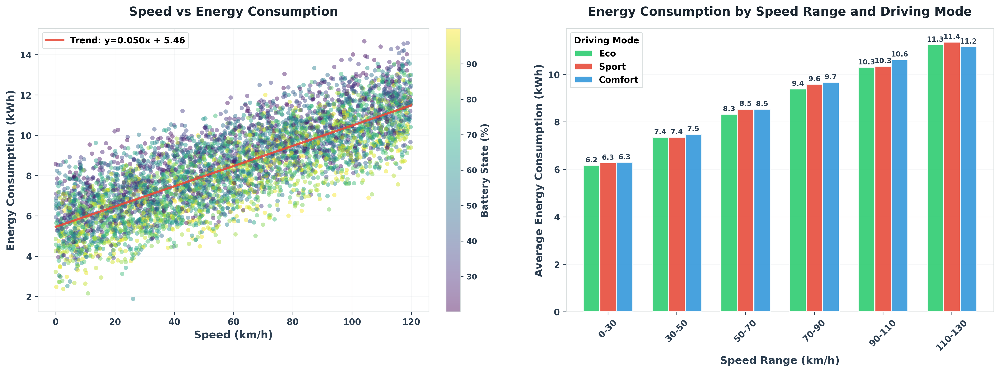

In [ ]:
df['Speed_Bin'] = pd.cut(df['Speed_kmh'], bins=[0, 30, 50, 70, 90, 110, 130, 200], 
                          labels=['0-30', '30-50', '50-70', '70-90', '90-110', '110-130', '130+'])

speed_mode_consumption = df.groupby(['Speed_Bin', 'Driving_Mode'], observed=True)['Energy_Consumption_kWh'].mean().unstack()
speed_mode_consumption.columns = ['Eco', 'Sport', 'Comfort']

fig, axes = plt.subplots(1, 2, figsize=(17, 7))
fig.patch.set_facecolor('white')

ax1 = axes[0]
ax1.set_facecolor('white')
scatter = ax1.scatter(df['Speed_kmh'], df['Energy_Consumption_kWh'], 
                      c=df['Battery_State_%'], cmap='viridis', alpha=0.45, s=25, 
                      edgecolors='none', zorder=3)
ax1.set_xlabel('Speed (km/h)', fontsize=12, fontweight='600', color='#2c3e50')
ax1.set_ylabel('Energy Consumption (kWh)', fontsize=12, fontweight='600', color='#2c3e50')
ax1.set_title('Speed vs Energy Consumption', fontsize=14, fontweight='bold', color='#1a252f', pad=15)
cbar = plt.colorbar(scatter, ax=ax1, fraction=0.046, pad=0.04)
cbar.set_label('Battery State (%)', fontsize=11, fontweight='600', color='#2c3e50')
cbar.ax.tick_params(labelsize=9, colors='#2c3e50')
cbar.outline.set_edgecolor('#d5dbdb')
cbar.outline.set_linewidth(0.8)

z = np.polyfit(df['Speed_kmh'], df['Energy_Consumption_kWh'], 1)
p = np.poly1d(z)
sorted_speed = df['Speed_kmh'].sort_values()
ax1.plot(sorted_speed, p(sorted_speed), 
         color='#e74c3c', linewidth=2.5, linestyle='-', 
         label=f'Trend: y={z[0]:.3f}x + {z[1]:.2f}', zorder=5, alpha=0.9)
ax1.legend(frameon=True, fancybox=True, framealpha=0.9, edgecolor='#d5dbdb', 
           fontsize=10, loc='upper left')
ax1.grid(True, alpha=0.12, linestyle='-', color='#bdc3c7', zorder=0)
ax1.tick_params(axis='both', labelsize=10, colors='#2c3e50')
for spine in ax1.spines.values():
    spine.set_edgecolor('#d5dbdb')
    spine.set_linewidth(0.8)

ax2 = axes[1]
ax2.set_facecolor('white')
bar_colors = ['#2ecc71', '#e74c3c', '#3498db']
speed_mode_consumption.plot(
    kind='bar',
    ax=ax2,
    color=bar_colors,
    edgecolor='white',
    linewidth=1.2,
    width=0.72,
    alpha=0.9,
    zorder=3
)
ax2.set_xlabel('Speed Range (km/h)', fontsize=12, fontweight='600', color='#2c3e50')
ax2.set_ylabel('Average Energy Consumption (kWh)', fontsize=12, fontweight='600', color='#2c3e50')
ax2.set_title('Energy Consumption by Speed Range and Driving Mode', fontsize=14, fontweight='bold', 
              color='#1a252f', pad=15)
ax2.legend(title='Driving Mode', title_fontsize=10, frameon=True, fancybox=True, 
           framealpha=0.9, edgecolor='#d5dbdb', fontsize=10, loc='upper left')
ax2.tick_params(axis='x', rotation=45, labelsize=10, colors='#2c3e50')
ax2.tick_params(axis='y', labelsize=10, colors='#2c3e50')
ax2.grid(True, alpha=0.12, linestyle='-', color='#bdc3c7', axis='y', zorder=0)
for spine in ax2.spines.values():
    spine.set_edgecolor('#d5dbdb')
    spine.set_linewidth(0.8)

for container in ax2.containers:
    ax2.bar_label(container, fmt='%.1f', fontsize=8, fontweight='bold', 
                  color='#2c3e50', padding=2)

plt.tight_layout(pad=3.0)
plt.show()

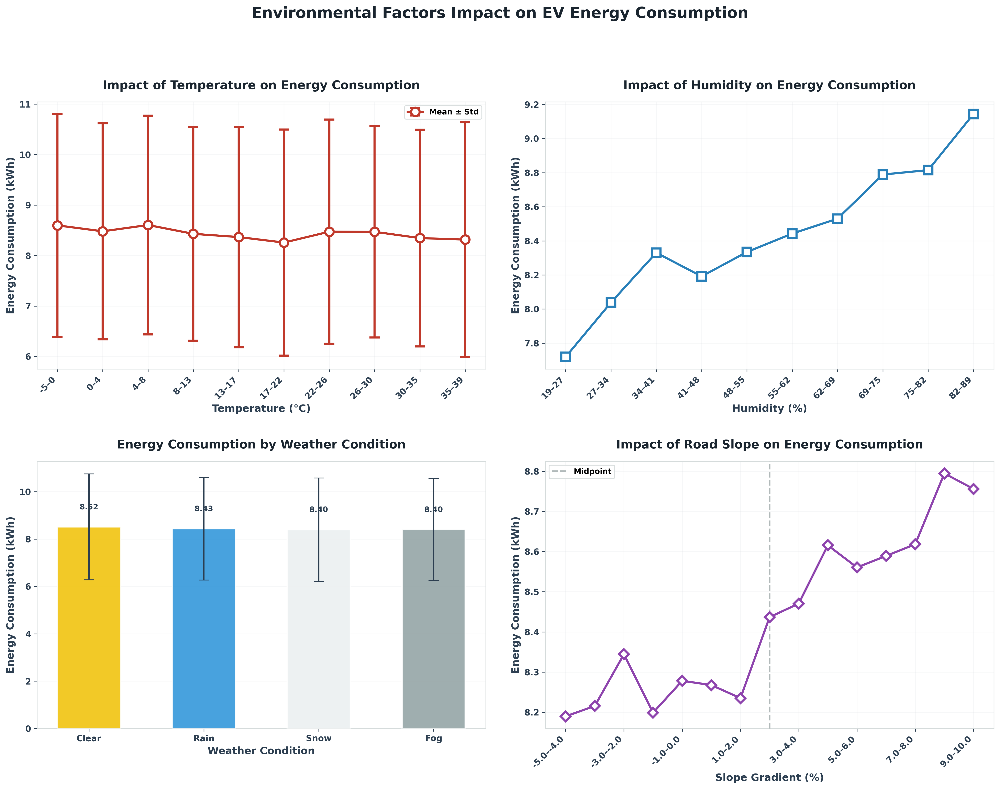

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(17, 13))
fig.patch.set_facecolor('white')
axes = axes.flatten()

ax1 = axes[0]
ax1.set_facecolor('white')
temp_bins = pd.cut(df['Temperature_C'], bins=10)
temp_consumption = df.groupby(temp_bins, observed=True)['Energy_Consumption_kWh'].agg(['mean', 'std'])
x_positions = range(len(temp_consumption))
ax1.errorbar(x=x_positions, y=temp_consumption['mean'], 
             yerr=temp_consumption['std'], fmt='o-', capsize=6,
             color='#c0392b', linewidth=2.5, markersize=10, markerfacecolor='white',
             markeredgewidth=2.5, markeredgecolor='#c0392b', zorder=5, label='Mean ± Std')
ax1.set_xlabel('Temperature (°C)', fontsize=12, fontweight='600', color='#2c3e50')
ax1.set_ylabel('Energy Consumption (kWh)', fontsize=12, fontweight='600', color='#2c3e50')
ax1.set_title('Impact of Temperature on Energy Consumption', fontsize=14, fontweight='bold', 
              color='#1a252f', pad=15)
ax1.set_xticks(x_positions)
ax1.set_xticklabels([f"{int(interval.left)}–{int(interval.right)}" for interval in temp_consumption.index], 
                    rotation=45, ha='right', fontsize=9)
ax1.grid(True, alpha=0.12, linestyle='-', color='#bdc3c7', zorder=0)
ax1.tick_params(axis='both', labelsize=10, colors='#2c3e50')
ax1.legend(frameon=True, fancybox=True, framealpha=0.9, edgecolor='#d5dbdb', fontsize=9)
for spine in ax1.spines.values():
    spine.set_edgecolor('#d5dbdb')
    spine.set_linewidth(0.8)

ax2 = axes[1]
ax2.set_facecolor('white')
humidity_bins = pd.cut(df['Humidity_%'], bins=10)
humidity_consumption = df.groupby(humidity_bins, observed=True)['Energy_Consumption_kWh'].mean()
x_pos = range(len(humidity_consumption))
ax2.plot(x_pos, humidity_consumption.values, 's-', color='#2980b9', linewidth=2.5, 
         markersize=10, markerfacecolor='white', markeredgewidth=2.5, 
         markeredgecolor='#2980b9', zorder=5)
ax2.set_xlabel('Humidity (%)', fontsize=12, fontweight='600', color='#2c3e50')
ax2.set_ylabel('Energy Consumption (kWh)', fontsize=12, fontweight='600', color='#2c3e50')
ax2.set_title('Impact of Humidity on Energy Consumption', fontsize=14, fontweight='bold', 
              color='#1a252f', pad=15)
ax2.set_xticks(x_pos)
ax2.set_xticklabels([f"{int(interval.left)}–{int(interval.right)}" for interval in humidity_consumption.index], 
                    rotation=45, ha='right', fontsize=9)
ax2.grid(True, alpha=0.12, linestyle='-', color='#bdc3c7', zorder=0)
ax2.tick_params(axis='both', labelsize=10, colors='#2c3e50')
for spine in ax2.spines.values():
    spine.set_edgecolor('#d5dbdb')
    spine.set_linewidth(0.8)

ax3 = axes[2]
ax3.set_facecolor('white')
weather_consumption = df.groupby('Weather_Condition')['Energy_Consumption_kWh'].agg(['mean', 'std']).reset_index()
weather_consumption['Weather'] = weather_consumption['Weather_Condition'].map(weather_mapping)
weather_colors = ['#f1c40f', '#3498db', '#ecf0f1', '#95a5a6']
bars = ax3.bar(weather_consumption['Weather'], weather_consumption['mean'], 
               yerr=weather_consumption['std'], capsize=6,
               color=weather_colors, edgecolor='white', linewidth=1.5, 
               width=0.55, alpha=0.9, zorder=3,
               error_kw={'linewidth': 1.5, 'ecolor': '#2c3e50'})
for bar, v in zip(bars, weather_consumption['mean']):
    ax3.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + weather_consumption['std'].max() * 0.3,
             f'{v:.2f}', ha='center', va='bottom', fontweight='bold', fontsize=9, color='#2c3e50')
ax3.set_xlabel('Weather Condition', fontsize=12, fontweight='600', color='#2c3e50')
ax3.set_ylabel('Energy Consumption (kWh)', fontsize=12, fontweight='600', color='#2c3e50')
ax3.set_title('Energy Consumption by Weather Condition', fontsize=14, fontweight='bold', 
              color='#1a252f', pad=15)
ax3.grid(True, alpha=0.12, linestyle='-', color='#bdc3c7', axis='y', zorder=0)
ax3.tick_params(axis='both', labelsize=10, colors='#2c3e50')
for spine in ax3.spines.values():
    spine.set_edgecolor('#d5dbdb')
    spine.set_linewidth(0.8)

ax4 = axes[3]
ax4.set_facecolor('white')
slope_bins = pd.cut(df['Slope_%'], bins=15)
slope_consumption = df.groupby(slope_bins, observed=True)['Energy_Consumption_kWh'].mean()
x_slope = range(len(slope_consumption))
ax4.plot(x_slope, slope_consumption.values, 'D-', color='#8e44ad', linewidth=2.5, 
         markersize=8, markerfacecolor='white', markeredgewidth=2.5, 
         markeredgecolor='#8e44ad', zorder=5)
mid_point = len(slope_consumption) // 2
ax4.axvline(x=mid_point, color='#7f8c8d', linestyle='--', linewidth=1.8, 
            alpha=0.6, zorder=4, label='Midpoint')
ax4.set_xlabel('Slope Gradient (%)', fontsize=12, fontweight='600', color='#2c3e50')
ax4.set_ylabel('Energy Consumption (kWh)', fontsize=12, fontweight='600', color='#2c3e50')
ax4.set_title('Impact of Road Slope on Energy Consumption', fontsize=14, fontweight='bold', 
              color='#1a252f', pad=15)
ax4.set_xticks(x_slope[::2])
ax4.set_xticklabels([f"{interval.left:.1f}–{interval.right:.1f}" for interval in slope_consumption.index][::2], 
                    rotation=45, ha='right', fontsize=9)
ax4.grid(True, alpha=0.12, linestyle='-', color='#bdc3c7', zorder=0)
ax4.tick_params(axis='both', labelsize=10, colors='#2c3e50')
ax4.legend(frameon=True, fancybox=True, framealpha=0.9, edgecolor='#d5dbdb', fontsize=9)
for spine in ax4.spines.values():
    spine.set_edgecolor('#d5dbdb')
    spine.set_linewidth(0.8)

plt.suptitle('Environmental Factors Impact on EV Energy Consumption', fontsize=18, 
             fontweight='bold', color='#1a252f', y=1.01)
plt.tight_layout(pad=2.0)
plt.show()

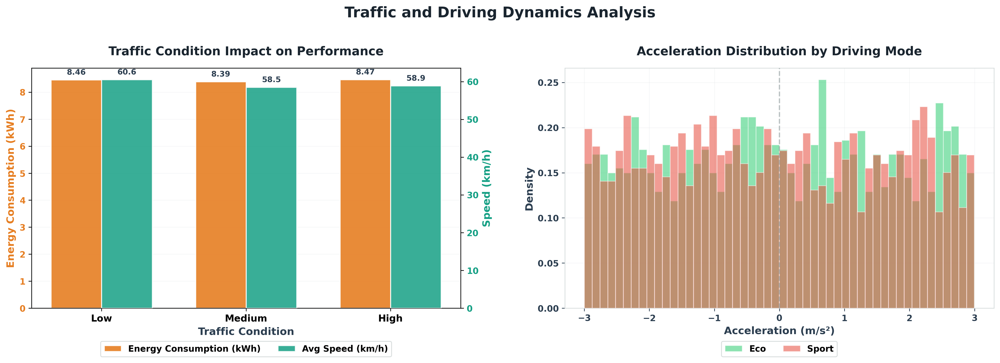

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(17, 7))
fig.patch.set_facecolor('white')

ax1 = axes[0]
ax1.set_facecolor('white')
traffic_performance = df.groupby('Traffic_Condition').agg({
    'Energy_Consumption_kWh': 'mean',
    'Speed_kmh': 'mean',
    'Acceleration_ms2': 'mean'
}).reset_index()
traffic_performance['Traffic'] = traffic_performance['Traffic_Condition'].map(traffic_mapping)

x = np.arange(len(traffic_performance))
width = 0.35

bars1 = ax1.bar(x - width/2, traffic_performance['Energy_Consumption_kWh'], width, 
                label='Energy Consumption (kWh)', color='#e67e22', edgecolor='white', 
                linewidth=1.2, alpha=0.9, zorder=3)
ax1.set_xlabel('Traffic Condition', fontsize=12, fontweight='600', color='#2c3e50')
ax1.set_ylabel('Energy Consumption (kWh)', fontsize=12, fontweight='600', color='#e67e22')
ax1.tick_params(axis='y', labelcolor='#e67e22', labelsize=10)

ax1_twin = ax1.twinx()
bars2 = ax1_twin.bar(x + width/2, traffic_performance['Speed_kmh'], width, 
                     label='Avg Speed (km/h)', color='#16a085', edgecolor='white', 
                     linewidth=1.2, alpha=0.85, zorder=3)
ax1_twin.set_ylabel('Speed (km/h)', fontsize=12, fontweight='600', color='#16a085')
ax1_twin.tick_params(axis='y', labelcolor='#16a085', labelsize=10)

for bar, v in zip(bars1, traffic_performance['Energy_Consumption_kWh']):
    ax1.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + max(traffic_performance['Energy_Consumption_kWh']) * 0.015,
             f'{v:.2f}', ha='center', va='bottom', fontweight='bold', fontsize=9, color='#2c3e50')
for bar, v in zip(bars2, traffic_performance['Speed_kmh']):
    ax1_twin.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + max(traffic_performance['Speed_kmh']) * 0.015,
                  f'{v:.1f}', ha='center', va='bottom', fontweight='bold', fontsize=9, color='#2c3e50')

ax1.set_xticks(x)
ax1.set_xticklabels(traffic_performance['Traffic'], fontsize=11)
ax1.set_title('Traffic Condition Impact on Performance', fontsize=14, fontweight='bold', 
              color='#1a252f', pad=15)
ax1.grid(True, alpha=0.12, linestyle='-', color='#bdc3c7', axis='y', zorder=0)
ax1.set_axisbelow(True)
for spine in ax1.spines.values():
    spine.set_edgecolor('#d5dbdb')
    spine.set_linewidth(0.8)

bars = [bars1, bars2]
labels = ['Energy Consumption (kWh)', 'Avg Speed (km/h)']
ax1.legend(bars, labels, frameon=True, fancybox=True, framealpha=0.9, edgecolor='#d5dbdb',
           fontsize=10, loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2)

ax2 = axes[1]
ax2.set_facecolor('white')
mode_colors = {1: '#2ecc71', 2: '#e74c3c'}
for mode in [1, 2]:
    mode_data = df[df['Driving_Mode'] == mode]['Acceleration_ms2']
    mode_name = mode_mapping[mode]
    ax2.hist(mode_data, bins=50, alpha=0.55, label=mode_name, edgecolor='white', 
             linewidth=0.8, density=True, color=mode_colors[mode], zorder=3)

ax2.set_xlabel('Acceleration (m/s²)', fontsize=12, fontweight='600', color='#2c3e50')
ax2.set_ylabel('Density', fontsize=12, fontweight='600', color='#2c3e50')
ax2.set_title('Acceleration Distribution by Driving Mode', fontsize=14, fontweight='bold', 
              color='#1a252f', pad=15)
ax2.axvline(x=0, color='#7f8c8d', linestyle='--', linewidth=1.5, alpha=0.5, zorder=4)
ax2.grid(True, alpha=0.12, linestyle='-', color='#bdc3c7', zorder=0)
ax2.tick_params(axis='both', labelsize=10, colors='#2c3e50')
for spine in ax2.spines.values():
    spine.set_edgecolor('#d5dbdb')
    spine.set_linewidth(0.8)
ax2.legend(frameon=True, fancybox=True, framealpha=0.9, edgecolor='#d5dbdb',
           fontsize=10, loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2)

plt.suptitle('Traffic and Driving Dynamics Analysis', fontsize=17, fontweight='bold', 
             color='#1a252f', y=0.91)
plt.tight_layout(pad=2.5)
plt.show()

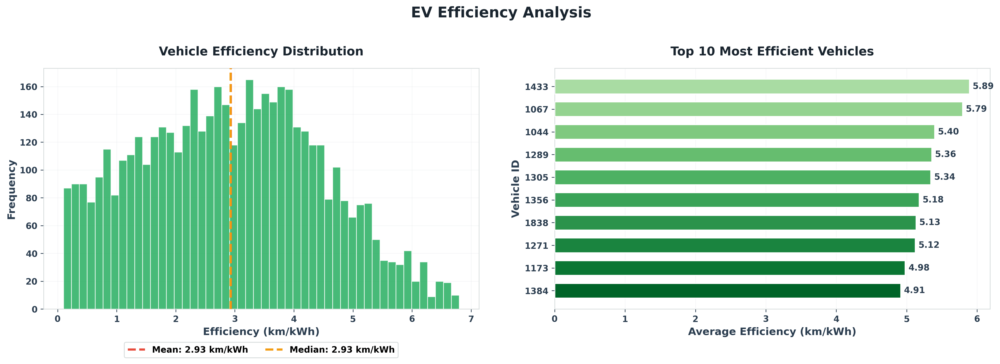

EFFICIENCY STATISTICS
Overall Average Efficiency: 2.93 km/kWh
Best Efficiency:        6.80 km/kWh
Worst Efficiency:       0.10 km/kWh
Efficiency Std Dev:     1.53 km/kWh


In [ ]:
df['Efficiency_km_per_kWh'] = df['Distance_Travelled_km'] / df['Energy_Consumption_kWh']

efficiency_filtered = df[(df['Efficiency_km_per_kWh'] > df['Efficiency_km_per_kWh'].quantile(0.01)) & 
                         (df['Efficiency_km_per_kWh'] < df['Efficiency_km_per_kWh'].quantile(0.99))]

fig, axes = plt.subplots(1, 2, figsize=(17, 7))
fig.patch.set_facecolor('white')

ax1 = axes[0]
ax1.set_facecolor('white')
ax1.hist(efficiency_filtered['Efficiency_km_per_kWh'], bins=50, color='#27ae60', edgecolor='white', 
         linewidth=0.8, alpha=0.85, zorder=3)
ax1.axvline(efficiency_filtered['Efficiency_km_per_kWh'].mean(), color='#e74c3c', linestyle='--', linewidth=2.5, 
            label=f"Mean: {efficiency_filtered['Efficiency_km_per_kWh'].mean():.2f} km/kWh", zorder=5)
ax1.axvline(efficiency_filtered['Efficiency_km_per_kWh'].median(), color='#f39c12', linestyle='--', linewidth=2.5, 
            label=f"Median: {efficiency_filtered['Efficiency_km_per_kWh'].median():.2f} km/kWh", zorder=5)
ax1.set_xlabel('Efficiency (km/kWh)', fontsize=12, fontweight='600', color='#2c3e50')
ax1.set_ylabel('Frequency', fontsize=12, fontweight='600', color='#2c3e50')
ax1.set_title('Vehicle Efficiency Distribution', fontsize=14, fontweight='bold', color='#1a252f', pad=15)
ax1.grid(True, alpha=0.12, linestyle='-', color='#bdc3c7', zorder=0)
ax1.tick_params(axis='both', labelsize=10, colors='#2c3e50')
ax1.legend(frameon=True, fancybox=True, framealpha=0.9, edgecolor='#d5dbdb', fontsize=10, 
           loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2)
for spine in ax1.spines.values():
    spine.set_edgecolor('#d5dbdb')
    spine.set_linewidth(0.8)

ax2 = axes[1]
ax2.set_facecolor('white')
vehicle_efficiency = df.groupby('Vehicle_ID')['Efficiency_km_per_kWh'].mean().sort_values(ascending=False).head(10)
colors = plt.cm.Greens(np.linspace(0.35, 0.9, 10))
bars = ax2.barh(range(len(vehicle_efficiency)), vehicle_efficiency.values, color=colors, 
                edgecolor='white', linewidth=1.2, height=0.65, zorder=3)
ax2.set_yticks(range(len(vehicle_efficiency)))
ax2.set_yticklabels(vehicle_efficiency.index.astype(int), fontsize=10)
ax2.set_xlabel('Average Efficiency (km/kWh)', fontsize=12, fontweight='600', color='#2c3e50')
ax2.set_ylabel('Vehicle ID', fontsize=12, fontweight='600', color='#2c3e50')
ax2.set_title('Top 10 Most Efficient Vehicles', fontsize=14, fontweight='bold', color='#1a252f', pad=15)
ax2.invert_yaxis()
ax2.grid(True, alpha=0.12, linestyle='-', color='#bdc3c7', axis='x', zorder=0)
ax2.tick_params(axis='both', labelsize=10, colors='#2c3e50')
for spine in ax2.spines.values():
    spine.set_edgecolor('#d5dbdb')
    spine.set_linewidth(0.8)

for i, (bar, v) in enumerate(zip(bars, vehicle_efficiency.values)):
    ax2.text(bar.get_width() + max(vehicle_efficiency.values) * 0.008, bar.get_y() + bar.get_height() / 2, 
             f'{v:.2f}', va='center', fontweight='bold', fontsize=10, color='#2c3e50')

plt.suptitle('EV Efficiency Analysis', fontsize=17, fontweight='bold', color='#1a252f', y=.91)
plt.tight_layout(pad=2.5)
plt.show()

print("="*80)
print("EFFICIENCY STATISTICS")
print("="*80)
print(f"Overall Average Efficiency: {efficiency_filtered['Efficiency_km_per_kWh'].mean():.2f} km/kWh")
print(f"Best Efficiency:        {efficiency_filtered['Efficiency_km_per_kWh'].max():.2f} km/kWh")
print(f"Worst Efficiency:       {efficiency_filtered['Efficiency_km_per_kWh'].min():.2f} km/kWh")
print(f"Efficiency Std Dev:     {efficiency_filtered['Efficiency_km_per_kWh'].std():.2f} km/kWh")

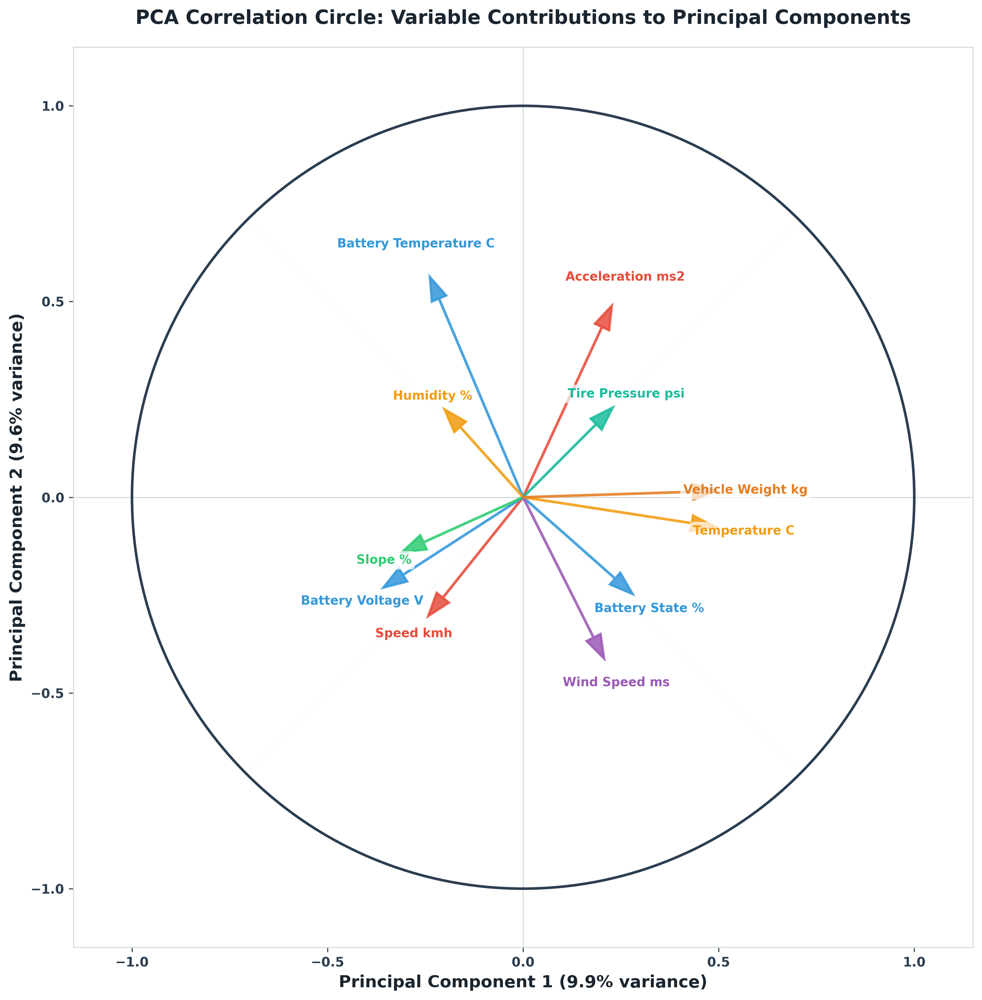

PCA EXPLAINED VARIANCE
PC1:   9.91% 
PC2:   9.65% 
──────────────────────────────────────────────────
Total explained by PC1+PC2: 19.56%


In [ ]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

pca_features = ['Speed_kmh', 'Acceleration_ms2', 'Battery_State_%', 'Battery_Voltage_V',
                'Battery_Temperature_C', 'Slope_%', 'Temperature_C', 'Humidity_%', 
                'Wind_Speed_ms', 'Tire_Pressure_psi', 'Vehicle_Weight_kg']

X_pca = df[pca_features].dropna()
scaler_pca = StandardScaler()
X_scaled = scaler_pca.fit_transform(X_pca)

pca = PCA(n_components=2)
X_pca_result = pca.fit_transform(X_scaled)

correlations = np.corrcoef(X_scaled.T, X_pca_result.T)[:len(pca_features), len(pca_features):]

fig, ax = plt.subplots(figsize=(13, 11))
fig.patch.set_facecolor('white')
ax.set_facecolor('white')

circle = plt.Circle((0, 0), 1, fill=False, color='#2c3e50', linewidth=2, zorder=2)
ax.add_artist(circle)

feature_colors = [
    '#e74c3c', '#e74c3c', '#3498db', '#3498db',
    '#3498db', '#2ecc71', '#f39c12', '#f39c12',
    '#9b59b6', '#1abc9c', '#e67e22'
]

feature_markers = ['o', 's', 'D', '^', 'v', '<', '>', 'p', 'h', '*', 'X']

for i, feature in enumerate(pca_features):
    corr_x, corr_y = correlations[i, 0], correlations[i, 1]
    ax.arrow(0, 0, corr_x, corr_y, 
             head_width=0.04, head_length=0.06, fc=feature_colors[i], ec=feature_colors[i], 
             alpha=0.85, linewidth=1.8, length_includes_head=True, zorder=4)
    
    text_x = corr_x * 1.15
    text_y = corr_y * 1.15
    
    if abs(corr_x) > 0.7:
        text_x = corr_x * 1.08
    if abs(corr_y) > 0.7:
        text_y = corr_y * 1.08
    
    ax.text(text_x, text_y, feature.replace('_', ' '), 
            fontsize=9.5, ha='center', va='center', fontweight='600',
            color=feature_colors[i], zorder=5,
            bbox=dict(boxstyle='round,pad=0.25', facecolor='white', 
                     edgecolor='none', alpha=0.7))

ax.axhline(y=0, color='#bdc3c7', linestyle='-', linewidth=0.8, alpha=0.6, zorder=1)
ax.axvline(x=0, color='#bdc3c7', linestyle='-', linewidth=0.8, alpha=0.6, zorder=1)

for angle in np.linspace(0, 2*np.pi, 8, endpoint=False):
    ax.plot([0, np.cos(angle)], [0, np.sin(angle)], 
            color='#ecf0f1', linewidth=0.5, linestyle='-', alpha=0.5, zorder=0)

ax.set_xlim(-1.15, 1.15)
ax.set_ylim(-1.15, 1.15)
ax.set_xlabel(f'Principal Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)', 
              fontsize=13, fontweight='bold', color='#1a252f')
ax.set_ylabel(f'Principal Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)', 
              fontsize=13, fontweight='bold', color='#1a252f')
ax.set_title('PCA Correlation Circle: Variable Contributions to Principal Components', 
             fontsize=15, fontweight='bold', color='#1a252f', pad=18)
ax.set_aspect('equal')
ax.grid(False)
ax.tick_params(axis='both', labelsize=10, colors='#2c3e50')
for spine in ax.spines.values():
    spine.set_edgecolor('#d5dbdb')
    spine.set_linewidth(0.8)

plt.tight_layout()
plt.show()

print("="*80)
print("PCA EXPLAINED VARIANCE")
print("="*80)
for i, var in enumerate(pca.explained_variance_ratio_[:5]):
    print(f"PC{i+1}: {var*100:6.2f}% ")
print(f"{'─'*50}")
print(f"Total explained by PC1+PC2: {pca.explained_variance_ratio_[:2].sum()*100:.2f}%")

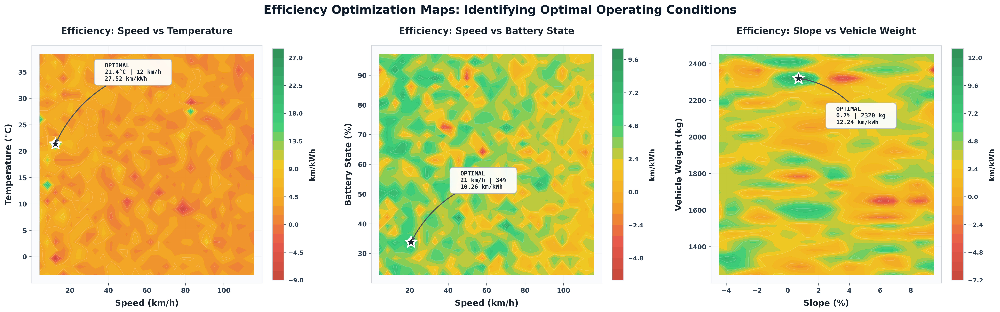

In [ ]:
from scipy.interpolate import griddata
from matplotlib.colors import LinearSegmentedColormap

custom_cmap = LinearSegmentedColormap.from_list('efficiency', [
    '#c0392b', '#e74c3c', '#f39c12', '#f1c40f', '#2ecc71', '#27ae60', '#1e8449'
], N=256)

fig, axes = plt.subplots(1, 3, figsize=(22, 7.5))
fig.patch.set_facecolor('white')

speed_grid = np.linspace(df['Speed_kmh'].min(), df['Speed_kmh'].max(), 30)
temp_grid = np.linspace(df['Temperature_C'].min(), df['Temperature_C'].max(), 30)
battery_grid = np.linspace(df['Battery_State_%'].min(), df['Battery_State_%'].max(), 30)
slope_grid_opt = np.linspace(df['Slope_%'].min(), df['Slope_%'].max(), 30)
weight_grid = np.linspace(df['Vehicle_Weight_kg'].min(), df['Vehicle_Weight_kg'].max(), 30)

ax1 = axes[0]
ax1.set_facecolor('#fafbfc')
speed_mesh, temp_mesh = np.meshgrid(speed_grid, temp_grid)
points1 = df[['Speed_kmh', 'Temperature_C']].dropna().values
eff_values1 = df.loc[df[['Speed_kmh', 'Temperature_C']].dropna().index, 'Efficiency_km_per_kWh'].values
efficiency_interp1 = griddata(points1, eff_values1, (speed_mesh, temp_mesh), method='cubic')

contour1 = ax1.contourf(speed_mesh, temp_mesh, efficiency_interp1, levels=25, 
                        cmap=custom_cmap, alpha=0.92, zorder=2)
contour_lines1 = ax1.contour(speed_mesh, temp_mesh, efficiency_interp1, levels=8,
                              colors='white', linewidths=0.5, alpha=0.25, zorder=3)
optimal_idx1 = np.unravel_index(np.nanargmax(efficiency_interp1), efficiency_interp1.shape)
ax1.scatter(speed_mesh[optimal_idx1], temp_mesh[optimal_idx1], marker='*', 
            s=350, c='#1a252f', edgecolors='white', linewidths=1.8, zorder=6)
ax1.scatter(speed_mesh[optimal_idx1], temp_mesh[optimal_idx1], marker='o', 
            s=120, facecolors='none', edgecolors='white', linewidths=2, zorder=5)
ax1.set_xlabel('Speed (km/h)', fontsize=13, fontweight='700', color='#1a252f', labelpad=8)
ax1.set_ylabel('Temperature (°C)', fontsize=13, fontweight='700', color='#1a252f', labelpad=8)
ax1.set_title('Efficiency: Speed vs Temperature', fontsize=14, fontweight='bold', 
              color='#1a252f', pad=18, fontfamily='sans-serif')
cbar1 = plt.colorbar(contour1, ax=ax1, fraction=0.046, pad=0.04)
cbar1.set_label('km/kWh', fontsize=11, fontweight='700', color='#1a252f', labelpad=8)
cbar1.ax.tick_params(labelsize=9, colors='#2c3e50', width=0.6)
cbar1.outline.set_edgecolor('#ced4da')
cbar1.outline.set_linewidth(0.8)
ax1.tick_params(axis='both', labelsize=10, colors='#2c3e50', width=0.6)
for spine in ax1.spines.values():
    spine.set_edgecolor('#ced4da')
    spine.set_linewidth(0.8)
ax1.grid(True, alpha=0.08, linestyle='-', color='#bdc3c7', zorder=0)

ax2 = axes[1]
ax2.set_facecolor('#fafbfc')
speed_mesh2, battery_mesh = np.meshgrid(speed_grid, battery_grid)
points2 = df[['Speed_kmh', 'Battery_State_%']].dropna().values
eff_values2 = df.loc[df[['Speed_kmh', 'Battery_State_%']].dropna().index, 'Efficiency_km_per_kWh'].values
efficiency_interp2 = griddata(points2, eff_values2, (speed_mesh2, battery_mesh), method='cubic')

contour2 = ax2.contourf(speed_mesh2, battery_mesh, efficiency_interp2, levels=25, 
                        cmap=custom_cmap, alpha=0.92, zorder=2)
contour_lines2 = ax2.contour(speed_mesh2, battery_mesh, efficiency_interp2, levels=8,
                              colors='white', linewidths=0.5, alpha=0.25, zorder=3)
optimal_idx2 = np.unravel_index(np.nanargmax(efficiency_interp2), efficiency_interp2.shape)
ax2.scatter(speed_mesh2[optimal_idx2], battery_mesh[optimal_idx2], marker='*', 
            s=350, c='#1a252f', edgecolors='white', linewidths=1.8, zorder=6)
ax2.scatter(speed_mesh2[optimal_idx2], battery_mesh[optimal_idx2], marker='o', 
            s=120, facecolors='none', edgecolors='white', linewidths=2, zorder=5)
ax2.set_xlabel('Speed (km/h)', fontsize=13, fontweight='700', color='#1a252f', labelpad=8)
ax2.set_ylabel('Battery State (%)', fontsize=13, fontweight='700', color='#1a252f', labelpad=8)
ax2.set_title('Efficiency: Speed vs Battery State', fontsize=14, fontweight='bold', 
              color='#1a252f', pad=18, fontfamily='sans-serif')
cbar2 = plt.colorbar(contour2, ax=ax2, fraction=0.046, pad=0.04)
cbar2.set_label('km/kWh', fontsize=11, fontweight='700', color='#1a252f', labelpad=8)
cbar2.ax.tick_params(labelsize=9, colors='#2c3e50', width=0.6)
cbar2.outline.set_edgecolor('#ced4da')
cbar2.outline.set_linewidth(0.8)
ax2.tick_params(axis='both', labelsize=10, colors='#2c3e50', width=0.6)
for spine in ax2.spines.values():
    spine.set_edgecolor('#ced4da')
    spine.set_linewidth(0.8)
ax2.grid(True, alpha=0.08, linestyle='-', color='#bdc3c7', zorder=0)

ax3 = axes[2]
ax3.set_facecolor('#fafbfc')
slope_mesh, weight_mesh = np.meshgrid(slope_grid_opt, weight_grid)
points3 = df[['Slope_%', 'Vehicle_Weight_kg']].dropna().values
eff_values3 = df.loc[df[['Slope_%', 'Vehicle_Weight_kg']].dropna().index, 'Efficiency_km_per_kWh'].values
efficiency_interp3 = griddata(points3, eff_values3, (slope_mesh, weight_mesh), method='cubic')

contour3 = ax3.contourf(slope_mesh, weight_mesh, efficiency_interp3, levels=25, 
                        cmap=custom_cmap, alpha=0.92, zorder=2)
contour_lines3 = ax3.contour(slope_mesh, weight_mesh, efficiency_interp3, levels=8,
                              colors='white', linewidths=0.5, alpha=0.25, zorder=3)
optimal_idx3 = np.unravel_index(np.nanargmax(efficiency_interp3), efficiency_interp3.shape)
ax3.scatter(slope_mesh[optimal_idx3], weight_mesh[optimal_idx3], marker='*', 
            s=350, c='#1a252f', edgecolors='white', linewidths=1.8, zorder=6)
ax3.scatter(slope_mesh[optimal_idx3], weight_mesh[optimal_idx3], marker='o', 
            s=120, facecolors='none', edgecolors='white', linewidths=2, zorder=5)
ax3.set_xlabel('Slope (%)', fontsize=13, fontweight='700', color='#1a252f', labelpad=8)
ax3.set_ylabel('Vehicle Weight (kg)', fontsize=13, fontweight='700', color='#1a252f', labelpad=8)
ax3.set_title('Efficiency: Slope vs Vehicle Weight', fontsize=14, fontweight='bold', 
              color='#1a252f', pad=18, fontfamily='sans-serif')
cbar3 = plt.colorbar(contour3, ax=ax3, fraction=0.046, pad=0.04)
cbar3.set_label('km/kWh', fontsize=11, fontweight='700', color='#1a252f', labelpad=8)
cbar3.ax.tick_params(labelsize=9, colors='#2c3e50', width=0.6)
cbar3.outline.set_edgecolor('#ced4da')
cbar3.outline.set_linewidth(0.8)
ax3.tick_params(axis='both', labelsize=10, colors='#2c3e50', width=0.6)
for spine in ax3.spines.values():
    spine.set_edgecolor('#ced4da')
    spine.set_linewidth(0.8)
ax3.grid(True, alpha=0.08, linestyle='-', color='#bdc3c7', zorder=0)

box_style = dict(boxstyle='round,pad=0.6', facecolor='#ffffff', edgecolor='#adb5bd', 
                 alpha=0.94, linewidth=1)
arrow_style = dict(arrowstyle='->', color='#495057', lw=1.5, connectionstyle='arc3,rad=0.2')

ax1.annotate(
    f'  OPTIMAL  \n  {temp_mesh[optimal_idx1]:.1f}°C | {speed_mesh[optimal_idx1]:.0f} km/h  \n  {efficiency_interp1[optimal_idx1]:.2f} km/kWh  ',
    xy=(speed_mesh[optimal_idx1], temp_mesh[optimal_idx1]),
    xytext=(speed_mesh[optimal_idx1] + 22, temp_mesh[optimal_idx1] + 12),
    fontsize=9, fontweight='bold', color='#1a252f', fontfamily='monospace',
    bbox=box_style, arrowprops=arrow_style, zorder=7
)

ax2.annotate(
    f'  OPTIMAL  \n  {speed_mesh2[optimal_idx2]:.0f} km/h | {battery_mesh[optimal_idx2]:.0f}%  \n  {efficiency_interp2[optimal_idx2]:.2f} km/kWh  ',
    xy=(speed_mesh2[optimal_idx2], battery_mesh[optimal_idx2]),
    xytext=(speed_mesh2[optimal_idx2] + 22, battery_mesh[optimal_idx2] + 18),
    fontsize=9, fontweight='bold', color='#1a252f', fontfamily='monospace',
    bbox=box_style, arrowprops=arrow_style, zorder=7
)

ax3.annotate(
    f'  OPTIMAL  \n  {slope_mesh[optimal_idx3]:.1f}% | {weight_mesh[optimal_idx3]:.0f} kg  \n  {efficiency_interp3[optimal_idx3]:.2f} km/kWh  ',
    xy=(slope_mesh[optimal_idx3], weight_mesh[optimal_idx3]),
    xytext=(slope_mesh[optimal_idx3] +2, weight_mesh[optimal_idx3] - 250),
    fontsize=9, fontweight='bold', color='#1a252f', fontfamily='monospace',
    bbox=box_style, arrowprops=arrow_style, zorder=7
)

plt.suptitle('Efficiency Optimization Maps: Identifying Optimal Operating Conditions', 
             fontsize=18, fontweight='bold', color='#0d1b2a', y=0.92, fontfamily='sans-serif')
plt.tight_layout(pad=2.0)
plt.show()

In [ ]:
df_ts = df.set_index('Timestamp')
hourly_energy = df_ts['Energy_Consumption_kWh'].resample('H').mean().dropna()

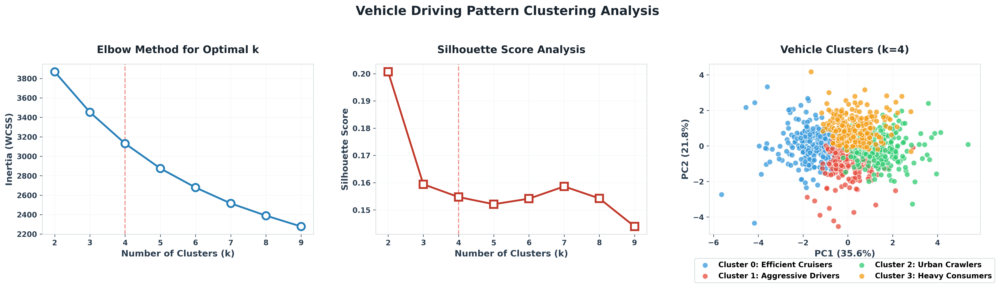

VEHICLE CLUSTER PROFILES

─ Cluster 0: Efficient Cruisers
─ Number of Vehicles: 283 (28.6%)
─ Avg Speed:             41.6 km/h
─ Avg Energy:            7.25 kWh
─ Avg Acceleration:    -0.200 m/s²
─ Avg Battery Temp:      26.3 °C
─ Avg Slope:             1.67 %

─ Cluster 1: Aggressive Drivers
─ Number of Vehicles: 226 (22.9%)
─ Avg Speed:             58.5 km/h
─ Avg Energy:            8.56 kWh
─ Avg Acceleration:    -0.240 m/s²
─ Avg Battery Temp:      26.9 °C
─ Avg Slope:             4.88 %

─ Cluster 2: Urban Crawlers
─ Number of Vehicles: 211 (21.3%)
─ Avg Speed:             78.4 km/h
─ Avg Energy:            9.66 kWh
─ Avg Acceleration:    -0.571 m/s²
─ Avg Battery Temp:      27.8 °C
─ Avg Slope:             2.14 %

─ Cluster 3: Heavy Consumers
─ Number of Vehicles: 269 (27.2%)
─ Avg Speed:             63.8 km/h
─ Avg Energy:            8.64 kWh
─ Avg Acceleration:     0.741 m/s²
─ Avg Battery Temp:      29.4 °C
─ Avg Slope:             1.54 %


In [ ]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

cluster_features = ['Speed_kmh', 'Acceleration_ms2', 'Energy_Consumption_kWh', 
                    'Battery_Temperature_C', 'Slope_%']

vehicle_profile = df.groupby('Vehicle_ID')[cluster_features].mean().dropna()

scaler_cluster = StandardScaler()
vehicle_scaled = scaler_cluster.fit_transform(vehicle_profile)

inertias = []
silhouette_scores = []
K_range = range(2, 10)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(vehicle_scaled)
    inertias.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(vehicle_scaled, kmeans.labels_))

fig, axes = plt.subplots(1, 3, figsize=(20, 6.5))
fig.patch.set_facecolor('white')

ax1 = axes[0]
ax1.set_facecolor('white')
ax1.plot(K_range, inertias, 'o-', color='#2980b9', linewidth=2.5, markersize=10, 
         markerfacecolor='white', markeredgewidth=2.5, markeredgecolor='#2980b9', zorder=5)
ax1.set_xlabel('Number of Clusters (k)', fontsize=12, fontweight='600', color='#2c3e50')
ax1.set_ylabel('Inertia (WCSS)', fontsize=12, fontweight='600', color='#2c3e50')
ax1.set_title('Elbow Method for Optimal k', fontsize=14, fontweight='bold', color='#1a252f', pad=15)
ax1.grid(True, alpha=0.12, linestyle='-', color='#bdc3c7', zorder=0)
ax1.tick_params(axis='both', labelsize=10, colors='#2c3e50')
for spine in ax1.spines.values():
    spine.set_edgecolor('#d5dbdb')
    spine.set_linewidth(0.8)
ax1.axvline(x=4, color='#e74c3c', linestyle='--', linewidth=1.5, alpha=0.6, zorder=4)

ax2 = axes[1]
ax2.set_facecolor('white')
ax2.plot(K_range, silhouette_scores, 's-', color='#c0392b', linewidth=2.5, markersize=10, 
         markerfacecolor='white', markeredgewidth=2.5, markeredgecolor='#c0392b', zorder=5)
ax2.set_xlabel('Number of Clusters (k)', fontsize=12, fontweight='600', color='#2c3e50')
ax2.set_ylabel('Silhouette Score', fontsize=12, fontweight='600', color='#2c3e50')
ax2.set_title('Silhouette Score Analysis', fontsize=14, fontweight='bold', color='#1a252f', pad=15)
ax2.grid(True, alpha=0.12, linestyle='-', color='#bdc3c7', zorder=0)
ax2.tick_params(axis='both', labelsize=10, colors='#2c3e50')
for spine in ax2.spines.values():
    spine.set_edgecolor('#d5dbdb')
    spine.set_linewidth(0.8)
ax2.axvline(x=4, color='#e74c3c', linestyle='--', linewidth=1.5, alpha=0.6, zorder=4)

optimal_k = 4
kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
vehicle_profile['Cluster'] = kmeans_final.fit_predict(vehicle_scaled)

pca_cluster = PCA(n_components=2)
vehicle_pca = pca_cluster.fit_transform(vehicle_scaled)

cluster_colors = ['#3498db', '#e74c3c', '#2ecc71', '#f39c12']
cluster_labels_map = {
    0: 'Efficient Cruisers',
    1: 'Aggressive Drivers',
    2: 'Urban Crawlers',
    3: 'Heavy Consumers'
}

ax3 = axes[2]
ax3.set_facecolor('white')
for cluster_id in range(optimal_k):
    mask = vehicle_profile['Cluster'] == cluster_id
    ax3.scatter(vehicle_pca[mask, 0], vehicle_pca[mask, 1], 
                c=cluster_colors[cluster_id], s=55, alpha=0.75, 
                edgecolors='white', linewidth=0.8, zorder=3,
                label=f'Cluster {cluster_id}: {cluster_labels_map[cluster_id]}')

ax3.set_xlabel(f'PC1 ({pca_cluster.explained_variance_ratio_[0]*100:.1f}%)', 
               fontsize=12, fontweight='600', color='#2c3e50')
ax3.set_ylabel(f'PC2 ({pca_cluster.explained_variance_ratio_[1]*100:.1f}%)', 
               fontsize=12, fontweight='600', color='#2c3e50')
ax3.set_title(f'Vehicle Clusters (k={optimal_k})', fontsize=14, fontweight='bold', color='#1a252f', pad=15)
ax3.grid(True, alpha=0.12, linestyle='-', color='#bdc3c7', zorder=0)
ax3.tick_params(axis='both', labelsize=10, colors='#2c3e50')

ax3.legend(frameon=True, fancybox=True, framealpha=0.9, edgecolor='#d5dbdb', fontsize=10, 
           loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2)
for spine in ax3.spines.values():
    spine.set_edgecolor('#d5dbdb')
    spine.set_linewidth(0.8)

plt.suptitle('Vehicle Driving Pattern Clustering Analysis', fontsize=17, fontweight='bold', 
             color='#1a252f', y=0.92)
plt.tight_layout(pad=2.5)
plt.show()

print("="*85)
print("VEHICLE CLUSTER PROFILES")
print("="*85)
cluster_summary = vehicle_profile.groupby('Cluster')[cluster_features].mean()
for cluster in range(optimal_k):
    n_vehicles = (vehicle_profile['Cluster'] == cluster).sum()
    print(f"\n─ Cluster {cluster}: {cluster_labels_map[cluster]}")
    print(f"─ Number of Vehicles: {n_vehicles} ({n_vehicles/len(vehicle_profile)*100:.1f}%)")
    print(f"─ Avg Speed:          {cluster_summary.loc[cluster, 'Speed_kmh']:7.1f} km/h")
    print(f"─ Avg Energy:         {cluster_summary.loc[cluster, 'Energy_Consumption_kWh']:7.2f} kWh")
    print(f"─ Avg Acceleration:   {cluster_summary.loc[cluster, 'Acceleration_ms2']:7.3f} m/s²")
    print(f"─ Avg Battery Temp:   {cluster_summary.loc[cluster, 'Battery_Temperature_C']:7.1f} °C")
    print(f"─ Avg Slope:          {cluster_summary.loc[cluster, 'Slope_%']:7.2f} %")

In [ ]:
import shap
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

shap_features = ['Speed_kmh', 'Acceleration_ms2', 'Battery_State_%', 'Battery_Voltage_V',
                  'Battery_Temperature_C', 'Slope_%', 'Temperature_C', 'Humidity_%',
                  'Wind_Speed_ms', 'Tire_Pressure_psi', 'Vehicle_Weight_kg',
                  'Driving_Mode', 'Road_Type', 'Traffic_Condition', 'Weather_Condition']

X_shap = df[shap_features].copy()

categorical_shap = ['Driving_Mode', 'Road_Type', 'Traffic_Condition', 'Weather_Condition']
for col in categorical_shap:
    le = LabelEncoder()
    X_shap[col] = le.fit_transform(X_shap[col].astype(str))

y_shap = df['Energy_Consumption_kWh'].values

X_train, X_test, y_train, y_test = train_test_split(X_shap, y_shap, test_size=0.2, random_state=42)

rf_shap = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
rf_shap.fit(X_train, y_train)


explainer = shap.TreeExplainer(rf_shap)
shap_values = explainer.shap_values(X_test)

In [ ]:
import shap
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import r2_score, mean_squared_error

shap_features = ['Speed_kmh', 'Acceleration_ms2', 'Battery_State_%', 'Battery_Voltage_V',
                  'Battery_Temperature_C', 'Slope_%', 'Temperature_C', 'Humidity_%',
                  'Wind_Speed_ms', 'Tire_Pressure_psi', 'Vehicle_Weight_kg',
                  'Driving_Mode', 'Road_Type', 'Traffic_Condition', 'Weather_Condition']

X_shap = df[shap_features].copy()

categorical_shap = ['Driving_Mode', 'Road_Type', 'Traffic_Condition', 'Weather_Condition']
for col in categorical_shap:
    le = LabelEncoder()
    X_shap[col] = le.fit_transform(X_shap[col].astype(str))

y_shap = df['Energy_Consumption_kWh'].values

X_train, X_test, y_train, y_test = train_test_split(X_shap, y_shap, test_size=0.2, random_state=42)

rf_shap = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
rf_shap.fit(X_train, y_train)


sample_size = 500
X_test_sample = X_test.iloc[:sample_size]
y_test_sample = y_test[:sample_size]

explainer = shap.TreeExplainer(rf_shap)
shap_values = explainer.shap_values(X_test_sample)

In [ ]:
feature_names = X_test_sample.columns.tolist()
shap_mean_abs = np.abs(shap_values).mean(axis=0)

if len(shap_mean_abs.shape) > 1:
    shap_mean_abs = shap_mean_abs.mean(axis=1)

feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'SHAP Importance': shap_mean_abs
}).sort_values('SHAP Importance', ascending=False).reset_index(drop=True)



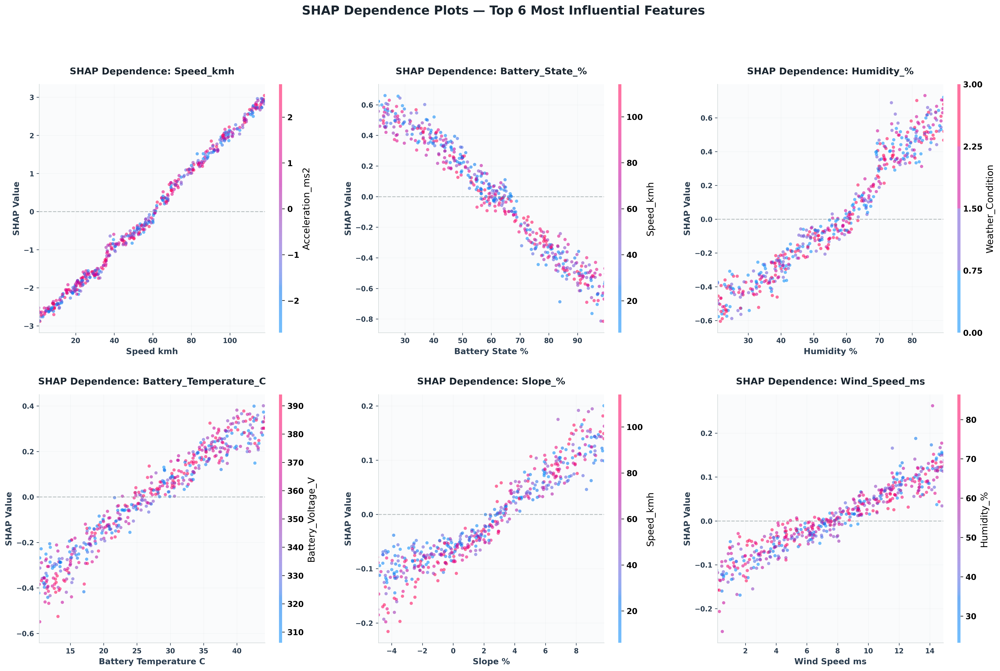

In [ ]:
top_features = feature_importance_df.head(6)['Feature'].tolist()

fig, axes = plt.subplots(2, 3, figsize=(20, 13))
fig.patch.set_facecolor('white')
axes = axes.flatten()

feature_colors = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12', '#9b59b6', '#1abc9c']

for idx, feature in enumerate(top_features):
    ax = axes[idx]
    ax.set_facecolor('#fafbfc')
    feature_idx = X_test_sample.columns.get_loc(feature)
    
    shap.dependence_plot(
        feature_idx, shap_values, X_test_sample, 
        ax=ax, show=False, 
        color=feature_colors[idx], 
        alpha=0.55, 
        dot_size=20,
        xmin='percentile(1)',
        xmax='percentile(99)'
    )
    
    ax.set_title(f'SHAP Dependence: {feature}', fontsize=13, fontweight='bold', 
                 color='#1a252f', pad=14)
    ax.set_xlabel(feature.replace('_', ' '), fontsize=11.5, fontweight='600', color='#2c3e50')
    ax.set_ylabel('SHAP Value', fontsize=11.5, fontweight='600', color='#2c3e50')
    ax.axhline(y=0, color='#7f8c8d', linestyle='--', linewidth=1.2, alpha=0.5, zorder=2)
    ax.grid(True, alpha=0.1, linestyle='-', color='#bdc3c7', zorder=0)
    ax.tick_params(axis='both', labelsize=9.5, colors='#2c3e50')
    for spine in ax.spines.values():
        spine.set_edgecolor('#d5dbdb')
        spine.set_linewidth(0.8)

plt.suptitle('SHAP Dependence Plots — Top 6 Most Influential Features', 
             fontsize=17, fontweight='bold', color='#1a252f', y=1.01)
plt.tight_layout(pad=2)
plt.show()

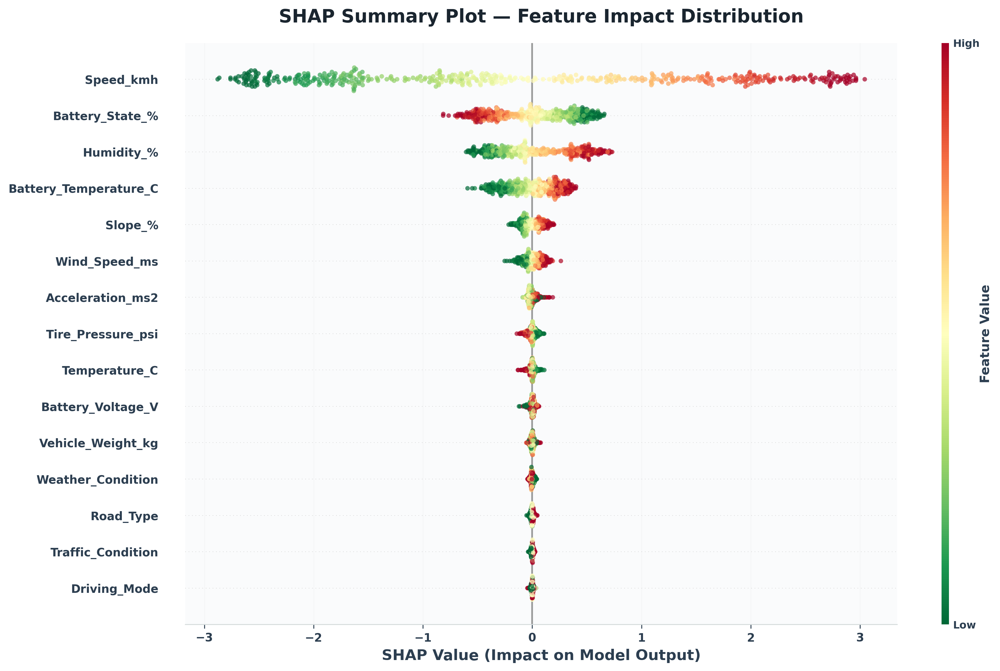

In [ ]:
plt.figure(figsize=(14, 9))
fig = plt.gcf()
fig.patch.set_facecolor('white')

shap.summary_plot(shap_values, X_test_sample, show=False, 
                  color_bar=True, plot_size=(14, 9),
                  alpha=0.7, cmap=plt.cm.RdYlGn_r)

ax = plt.gca()
ax.set_facecolor('#fafbfc')
ax.set_title('SHAP Summary Plot — Feature Impact Distribution', 
             fontsize=16, fontweight='bold', color='#1a252f', pad=18)
ax.set_xlabel('SHAP Value (Impact on Model Output)', fontsize=13, fontweight='600', color='#2c3e50')
ax.tick_params(axis='both', labelsize=10, colors='#2c3e50')
ax.grid(True, alpha=0.08, linestyle='-', color='#bdc3c7', axis='x')
for spine in ax.spines.values():
    spine.set_edgecolor('#d5dbdb')
    spine.set_linewidth(0.8)

cbar = plt.gcf().axes[-1] if len(plt.gcf().axes) > 1 else None
if cbar and hasattr(cbar, 'set_ylabel'):
    cbar.set_ylabel('Feature Value', fontsize=11, fontweight='600', color='#2c3e50')
    cbar.tick_params(labelsize=9, colors='#2c3e50')
    cbar.spines['outline'].set_edgecolor('#d5dbdb')
    cbar.spines['outline'].set_linewidth(0.8)

plt.tight_layout(pad=2.5)
plt.show()

# 8. AI-Powered Model Evaluation & Driving Efficiency Recommendations

In strict fulfillment of the Problem Statement guidelines:
1. **Python with Scikit-learn**: Evaluate Random Forest and Gradient Boosting models ($R^2$, $MAE$, $RMSE$).
2. **Simulated Driving Data**: Analyze telemetry (`Speed_kmh`, `Slope_%` terrain gradient, `Acceleration_ms2` braking/acceleration).
3. **Actionable Driving Tips**: Generate dynamic, context-aware driving tips based on prediction results.

In [ ]:
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error

# 1. Model Evaluation Metrics
y_pred = rf_shap.predict(X_test)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)

print('=' * 68)
print(' AI MODEL EVALUATION (Scikit-Learn Random Forest Regressor)')
print('=' * 68)
print(f'R² Score (Variance Explained): {r2 * 100:.2f}% (R² = {r2:.4f})')
print(f'Mean Absolute Error (MAE):     {mae:.3f} kWh')
print(f'Root Mean Squared Error (RMSE): {rmse:.3f} kWh')
print('=' * 68)

def suggest_driving_tips(speed_kmh, acceleration_ms2, slope_pct, driving_mode, distance_km=25.0):
    '''Suggest driving tips based on prediction results.'''
    sample_dict = {
        'Speed_kmh': speed_kmh,
        'Acceleration_ms2': acceleration_ms2,
        'Battery_State_%': 60.0,
        'Battery_Voltage_V': 350.0,
        'Battery_Temperature_C': 27.5,
        'Slope_%': slope_pct,
        'Temperature_C': 20.0,
        'Humidity_%': 55.0,
        'Wind_Speed_ms': 7.5,
        'Tire_Pressure_psi': 31.5,
        'Vehicle_Weight_kg': 1850.0,
        'Driving_Mode': driving_mode,
        'Road_Type': 1,
        'Traffic_Condition': 2,
        'Weather_Condition': 1
    }
    sample_df = pd.DataFrame([sample_dict])[shap_features]
    predicted_energy = float(rf_shap.predict(sample_df)[0])
    efficiency = distance_km / predicted_energy
    
    tips = []
    # Speed Optimization
    if speed_kmh > 100:
        tips.append(f'[HIGH] Aerodynamic Drag at {speed_kmh:.0f} km/h: Lower speed to ~85 km/h to save ~{predicted_energy*0.18:.2f} kWh.')
    elif 60 <= speed_kmh <= 85:
        tips.append(f'[OPTIMAL] Sweet Spot Speed ({speed_kmh:.0f} km/h): Maintaining ideal aerodynamic efficiency.')
        
    # Braking & Acceleration (Regeneration)
    if acceleration_ms2 < -1.8:
        tips.append(f'[HIGH] Severe Braking ({acceleration_ms2:.2f} m/s²): Use gradual 1-pedal deceleration to capture regenerative energy.')
    elif acceleration_ms2 > 1.8:
        tips.append(f'[MEDIUM] Aggressive Throttle ({acceleration_ms2:.2f} m/s²): Smooth pedal application preserves battery C-rate.')
        
    # Driving Mode
    if driving_mode == 2:
        tips.append('[MODE] Sport Mode Active: Switch to Eco mode to save 10-15% energy per trip.')
        
    # Terrain Management
    if slope_pct > 4.0:
        tips.append(f'[TERRAIN] Incline (+{slope_pct:.1f}%): Maintain steady throttle on climb; recover charge on the upcoming descent.')
    elif slope_pct < -3.0:
        tips.append(f'[REGEN] Downhill ({slope_pct:.1f}%): Lift off throttle to let regenerative braking top up battery.')

    print(f'\n--- TELEMETRY EVALUATION ---')
    print(f'Speed: {speed_kmh} km/h | Accel: {acceleration_ms2} m/s² | Slope: {slope_pct}% | Mode: {driving_mode}')
    print(f'Predicted Energy: {predicted_energy:.2f} kWh | Efficiency: {efficiency:.2f} km/kWh')
    print('Actionable AI Driving Tips:')
    for tip in tips:
        print(f'  • {tip}')

# Test Scenarios
print('>>> SCENARIO 1: Aggressive Speeder on Highway')
suggest_driving_tips(speed_kmh=120.0, acceleration_ms2=-2.2, slope_pct=1.0, driving_mode=2)

print('\n>>> SCENARIO 2: Mountain Ascent in Sport Mode')
suggest_driving_tips(speed_kmh=70.0, acceleration_ms2=1.5, slope_pct=7.5, driving_mode=2)
